# NYC Taxi Ride Duration: Does Weather Help?
**Negar Kamvij | CS672 Project 2 | Due November 13, 2026**

**Status: taxi and candidate-weather audits implemented. Models have not been trained. Weather is a retrospective reanalysis candidate, not a live observation feed.**

## Project objective
Build and compare TensorFlow models that predict NYC Yellow Taxi trip duration using taxi and weather data.

## My research question
Does adding weather information improve predictions for later taxi trips, especially during rainy or snowy periods?

## My expectation before training
I expect rain and snow to be associated with longer rides for similar routes and pickup times. This is a hypothesis to test, not a result. Weather may also change who travels and which routes they take. Trip duration is not a direct measurement of traffic.

## Prediction moment
The prediction is made when the ride starts and the destination is known. Candidate inputs are the pickup zone, destination zone, time, and weather information available then. Actual drop-off time, final fare, tips, tolls, and completed-trip distance are excluded from inputs. Pickup and destination zones are areas, not exact GPS points. An estimated route distance may be added later only if its source is documented and it is available before departure.


## 1. Assignment checklist
This checklist records the work required by the assignment. The notebook implements taxi and candidate-weather audits. Model experiments remain planned.

| Requirement | Planned evidence | Status |
| --- | --- | --- |
| Combine NYC taxi and weather data | Time-zone checks, weather definitions, merge coverage report | Candidate coverage and timing audit added; final modeling source pending |
| Prepare numeric inputs and scale features | Training-only preprocessing; documented categorical encoding | Planned |
| Time-sensitive 80/20 train/validation split | Chronological boundary and checks for overlapping rides | Planned |
| TensorFlow linear regression | Sequential model with no hidden layers | Planned |
| TensorFlow MLP | One hidden layer for a clear architecture comparison | Planned |
| TensorFlow DNN | At least two hidden layers | Planned |
| MSE and MAE losses | Experiment table | Planned |
| SGD, Adam, RMSProp; multiple learning rates | Reproducible experiment configurations | Planned |
| 100 epochs per fit; batch size 32 | Training logs | Planned |
| Training and validation loss after every fit | Saved curve for every run | Planned |
| Best model and parameters | Common validation metrics, exact configuration | Planned |
| `model.predict()` and error review | Predictions, MAE in minutes, RMSE, residuals | Planned |
| PyTorch extra credit | DNN with at least two hidden layers and fair framework comparison | Planned |

Additional investigation: weather versus no-weather inputs, rainy/dry error comparison, and examples of large prediction errors. If snow is rare or unavailable, report that limitation.

Source: CS672 Project 2 assignment supplied with this project. The PDF is not included in the public repository.


## 2. Setup
Open this notebook in Colab or another Jupyter-compatible environment. Run cells in order. The initial audit uses pandas, NumPy, PyArrow, and Matplotlib. If needed, run `%pip install pandas numpy pyarrow matplotlib` in a separate cell, then restart the runtime.

Raw files and trained models stay outside Git. The download cell uses the official TLC host and downloads only if the monthly file is missing. Downloading and auditing the full January file needs disk space and memory; it does not train a model.

January 2020 is the starting candidate because the assignment supplies a January weather example. This is a project choice, not a statement that January is mandatory. The audit and weather coverage will determine whether a longer period is needed for the weather question.


In [1]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
from urllib.request import urlretrieve
import json
import platform
import numpy as np
import pandas as pd

SEED = 672
TAXI_MONTH = "2020-01"
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
np.random.seed(SEED)
print("Python:", platform.python_version())
for package in ["pandas", "numpy", "pyarrow", "tensorflow", "torch"]:
    try:
        print(package, version(package))
    except PackageNotFoundError:
        print(package, "not installed; only needed when its section is implemented")
print("Audit month:", TAXI_MONTH)


Python: 3.12.14
pandas 2.2.3
numpy 2.3.5
pyarrow 26.0.0
tensorflow not installed; only needed when its section is implemented
torch not installed; only needed when its section is implemented
Audit month: 2020-01


## 3. Download the original taxi data
The source file stays unchanged. The audit reads selected columns from every row. Selecting columns reduces memory use and does not remove trips.


In [2]:
def download_taxi_month(month: str, data_dir: Path) -> Path:
    """Return a local TLC Parquet file, downloading it if missing.

    Args:
        month (str): Calendar month in YYYY-MM format.
        data_dir (Path): Directory for the original monthly file.
    Returns:
        Path: Path to the source Parquet file.
    Raises:
        ValueError: If the month format is invalid.
        OSError: If a file operation or download fails.
    """
    parsed = pd.Period(month, freq="M")
    if str(parsed) != month:
        raise ValueError("Use a month in YYYY-MM format")
    data_dir.mkdir(parents=True, exist_ok=True)
    destination = data_dir / f"yellow_tripdata_{month}.parquet"
    if not destination.exists():
        partial = destination.with_suffix(".parquet.part")
        urlretrieve(
            f"https://d37ci6vzurychx.cloudfront.net/trip-data/{destination.name}",
            partial,
        )
        partial.replace(destination)
    return destination

source_path = download_taxi_month(TAXI_MONTH, DATA_DIR)
audit_columns = [
    "tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance",
    "PULocationID", "DOLocationID", "passenger_count",
]
taxi_raw = pd.read_parquet(source_path, columns=audit_columns)
print("Original rows:", f"{len(taxi_raw):,}")
print("Columns:", taxi_raw.columns.tolist())
print(taxi_raw.head().to_string(index=False))


Original rows: 6,405,008
Columns: ['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'trip_distance', 'PULocationID', 'DOLocationID', 'passenger_count']
tpep_pickup_datetime tpep_dropoff_datetime  trip_distance  PULocationID  DOLocationID  passenger_count
 2020-01-01 00:28:15   2020-01-01 00:33:03            1.2           238           239              1.0
 2020-01-01 00:35:39   2020-01-01 00:43:04            1.2           239           238              1.0
 2020-01-01 00:47:41   2020-01-01 00:53:52            0.6           238           238              1.0
 2020-01-01 00:55:23   2020-01-01 01:00:14            0.8           238           151              1.0
 2020-01-01 00:01:58   2020-01-01 00:04:16            0.0           193           193              1.0


## 4. Preserve records and flag data issues
Duration is the difference between drop-off and pickup time. Durations at or below zero cannot be used as valid training labels. Long trips are flagged for investigation, not automatically deleted.

The prepared table retains every row. Flags are separate from prediction features. Completed-trip distance is used only for the data-quality audit at this stage, not as a pickup-time input.

Taxi timestamps are treated as local New York wall-clock times for this January audit. Before combining months or joining weather, verify the source time conventions and explicitly handle daylight-saving changes.


In [3]:
def audit_taxi_records(frame: pd.DataFrame, month: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Add audit fields without modifying the input or removing rows.

    Args:
        frame (pd.DataFrame): Selected source taxi columns.
        month (str): Expected pickup month in YYYY-MM format.
    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: Retained records and flag counts.
    """
    retained = frame.copy()
    pickup = pd.to_datetime(retained["tpep_pickup_datetime"], errors="coerce")
    dropoff = pd.to_datetime(retained["tpep_dropoff_datetime"], errors="coerce")
    duration = (dropoff - pickup).dt.total_seconds() / 60
    expected = pd.Period(month, freq="M")
    retained["duration_minutes"] = duration
    retained["flag_missing_timestamp"] = pickup.isna() | dropoff.isna()
    retained["flag_outside_pickup_month"] = ~(
        pickup.dt.year.eq(expected.year) & pickup.dt.month.eq(expected.month)
    )
    retained["flag_invalid_duration"] = ~np.isfinite(duration) | duration.le(0)
    retained["flag_duration_over_180_minutes"] = duration.gt(180)
    retained["flag_invalid_distance"] = (
        ~np.isfinite(retained["trip_distance"]) | retained["trip_distance"].lt(0)
    )
    retained["flag_zero_distance"] = retained["trip_distance"].eq(0)
    retained["flag_distance_over_100_miles"] = retained["trip_distance"].gt(100)
    retained["flag_missing_zone"] = retained[["PULocationID", "DOLocationID"]].isna().any(axis=1)
    flags = [column for column in retained if column.startswith("flag_")]
    report = retained[flags].sum().rename("flagged_rows").to_frame()
    report["percent_of_source"] = report["flagged_rows"] / len(retained) * 100
    assert len(retained) == len(frame)
    assert retained.index.equals(frame.index)
    return retained, report

taxi_audit, flag_report = audit_taxi_records(taxi_raw, TAXI_MONTH)
print(flag_report.to_string())
print("Rows removed:", len(taxi_raw) - len(taxi_audit))
print("Flag counts overlap: one row can have several flags.")
print(taxi_audit["duration_minutes"].describe(percentiles=[.01, .5, .95, .99]).to_string())
flag_report.to_csv(OUTPUT_DIR / "taxi_quality_flags.csv")


                                flagged_rows  percent_of_source
flag_missing_timestamp                     0           0.000000
flag_outside_pickup_month                212           0.003310
flag_invalid_duration                   4406           0.068790
flag_duration_over_180_minutes         13789           0.215285
flag_invalid_distance                   2338           0.036503
flag_zero_distance                     67862           1.059515
flag_distance_over_100_miles              21           0.000328
flag_missing_zone                          0           0.000000
Rows removed: 0
Flag counts overlap: one row can have several flags.
count    6.405008e+06
mean     1.595008e+01
std      6.322999e+01
min     -2.770367e+03
1%       8.666667e-01
50%      1.048333e+01
95%      3.305000e+01
99%      5.343333e+01
max      8.525117e+03


## 5. Candidate weather: source, units, and limitations
This audit uses **ERA5 reanalysis through Open-Meteo**, requested near Wall Street (40.7075, -74.0113). The assignment allows another weather source. The response grid location is recorded separately; this is not a measurement at every taxi pickup.

ERA5 reconstructs historical weather using observations and modeling. It is not an archived forecast or a record of what a live system knew at pickup. Therefore these data support a **retrospective weather study**, not a claim of point-in-time production accuracy. A live prediction system would need an observation or forecast source with documented availability times. Weather-source selection for the final model remains an explicit decision.

[Open-Meteo historical weather documentation](https://open-meteo.com/en/docs/historical-weather-api) defines:

| Field | Unit | Meaning |
| --- | --- | --- |
| temperature_2m | Celsius | Air temperature at the timestamp |
| relative_humidity_2m | percent | Relative humidity at the timestamp |
| precipitation | mm | Total precipitation in the preceding hour |
| rain | mm | Liquid precipitation in the preceding hour |
| snowfall | cm | New snowfall in the preceding hour, not snow depth |
| wind_speed_10m | km/h | Wind speed at the timestamp |
| surface_pressure | hPa | Surface pressure at the timestamp |

UTC weather times are converted to America/New_York for calendar checks. The requested interval includes padding around January. A preliminary taxi association uses the latest whole-hour weather timestamp at or before pickup. This respects the measurement interval but **does not fix reanalysis hindsight or establish real publication availability**. No future weather is filled into missing slots.

Weather classes use positive reported amounts: dry = zero total precipitation; rain = positive rain with no snow; snow = positive snowfall with no rain; mixed = both positive; other/trace = remaining precipitation; unknown = missing values. These are data definitions, not street-level observations. One trip is not an independent weather event; counts of distinct weather hours and days are also reported.


In [4]:
from urllib.parse import urlencode
from urllib.request import Request, urlopen
from datetime import datetime, timezone
from IPython.display import display
import matplotlib.pyplot as plt

WEATHER_VARIABLES = [
    "temperature_2m", "relative_humidity_2m", "precipitation", "rain",
    "snowfall", "wind_speed_10m", "surface_pressure",
]

def download_weather_candidate(data_dir: Path) -> dict:
    """Load a cached January ERA5 candidate or download it with provenance.

    Args:
        data_dir (Path): Directory for raw weather and source metadata.
    Returns:
        dict: Unmodified Open-Meteo response with hourly values and units.
    Raises:
        OSError: If the download or file write fails.
        ValueError: If the response cannot be decoded as JSON.
    """
    destination = data_dir / "weather_era5_2020-01.json"
    params = {
        "latitude": 40.7075, "longitude": -74.0113,
        "start_date": "2019-12-31", "end_date": "2020-02-01",
        "hourly": ",".join(WEATHER_VARIABLES), "models": "era5",
        "timezone": "UTC", "temperature_unit": "celsius",
        "wind_speed_unit": "kmh", "precipitation_unit": "mm",
    }
    url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(params)
    if not destination.exists():
        request = Request(url, headers={"User-Agent": "CS672-taxi-weather-study"})
        with urlopen(request, timeout=90) as response:
            payload = json.load(response)
        partial = destination.with_suffix(".json.part")
        partial.write_text(json.dumps(payload))
        partial.replace(destination)
        provenance = {
            "url": url, "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
            "dataset": "ERA5 reanalysis via Open-Meteo",
            "requested_latitude": 40.7075, "requested_longitude": -74.0113,
            "purpose": "Retrospective weather candidate; not a live feed or archived forecast",
            "documentation": "https://open-meteo.com/en/docs/historical-weather-api",
        }
        (data_dir / "weather_source.json").write_text(json.dumps(provenance, indent=2))
    return json.loads(destination.read_text())

weather_payload = download_weather_candidate(DATA_DIR)
weather = pd.DataFrame(weather_payload["hourly"])
weather["weather_time_utc"] = pd.to_datetime(weather.pop("time"), utc=True)
weather = weather.sort_values("weather_time_utc").reset_index(drop=True)
assert weather["weather_time_utc"].is_unique
assert weather["weather_time_utc"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
expected_units = {"temperature_2m": "°C", "relative_humidity_2m": "%",
                  "precipitation": "mm", "rain": "mm", "snowfall": "cm",
                  "wind_speed_10m": "km/h", "surface_pressure": "hPa"}
assert all(weather_payload["hourly_units"][key] == value for key, value in expected_units.items())
weather["weather_time_local"] = weather["weather_time_utc"].dt.tz_convert("America/New_York")
weather_january = weather.loc[weather["weather_time_local"].dt.strftime("%Y-%m").eq(TAXI_MONTH)].copy()
assert len(weather_january) == 31 * 24
print("January hourly timestamps:", len(weather_january))
print("Requested location: Wall Street area, 40.7075, -74.0113")
print("Returned grid location:", weather_payload["latitude"], weather_payload["longitude"])
print("Source: ERA5 reanalysis via Open-Meteo; not real-time weather")
display(pd.DataFrame({"unit": expected_units, "missing_hours": weather_january[WEATHER_VARIABLES].isna().sum()}))


January hourly timestamps: 744
Requested location: Wall Street area, 40.7075, -74.0113
Returned grid location: 40.75 -74.0
Source: ERA5 reanalysis via Open-Meteo; not real-time weather


,unit,missing_hours
temperature_2m,°C,0
relative_humidity_2m,%,0
precipitation,mm,0
rain,mm,0
snowfall,cm,0
wind_speed_10m,km/h,0
surface_pressure,hPa,0


Hours with any positive rain: 67
Hours with any positive snowfall: 17
A day can appear in several weather classes; day counts overlap.


,distinct_hours,distinct_days
weather_class,,
dry,664,31
mixed,4,2
rain,63,11
snow,13,3


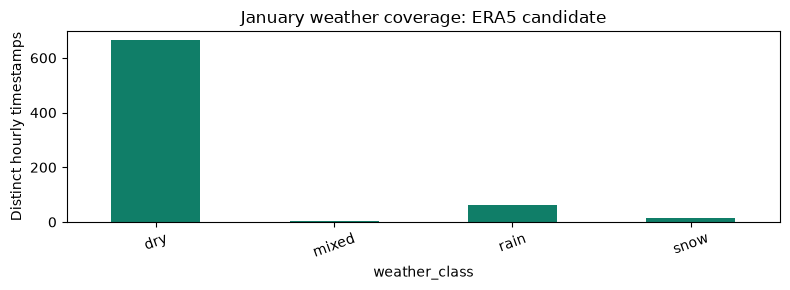

In [5]:
def classify_weather(frame: pd.DataFrame) -> pd.Series:
    """Classify reported precipitation without treating missing values as dry.

    Args:
        frame (pd.DataFrame): Hourly rain, snowfall, and precipitation fields.
    Returns:
        pd.Series: Nonoverlapping weather class labels aligned to input rows.
    """
    missing = frame[["rain", "snowfall", "precipitation"]].isna().any(axis=1)
    rain = frame["rain"].gt(0)
    snow = frame["snowfall"].gt(0)
    values = np.select(
        [missing, rain & snow, snow, rain, frame["precipitation"].eq(0)],
        ["unknown", "mixed", "snow", "rain", "dry"],
        default="other_or_trace",
    )
    return pd.Series(values, index=frame.index, name="weather_class")

weather["weather_class"] = classify_weather(weather)
weather_january["weather_class"] = classify_weather(weather_january)
weather_january["local_date"] = weather_january["weather_time_local"].dt.date
weather_exposure = weather_january.groupby("weather_class").agg(
    distinct_hours=("weather_time_utc", "size"),
    distinct_days=("local_date", "nunique"),
)
display(weather_exposure)
print("Hours with any positive rain:", int(weather_january["rain"].gt(0).sum()))
print("Hours with any positive snowfall:", int(weather_january["snowfall"].gt(0).sum()))
print("A day can appear in several weather classes; day counts overlap.")
weather_exposure["distinct_hours"].plot.bar(color="#107E68", figsize=(8, 3), rot=20)
plt.ylabel("Distinct hourly timestamps")
plt.title("January weather coverage: ERA5 candidate")
plt.tight_layout()
plt.show()
weather_exposure.to_csv(OUTPUT_DIR / "weather_exposure.csv")


## 6. Preliminary time split and weather association audit
This section checks whether a January-only 80/20 time split would contain rain and snow in both periods. It is not a trained model or the final feature table.

The eligibility mask uses an intended-month pickup and a finite, positive duration. It does not delete source rows and does not remove long rides by a fixed cutoff. Any other model input eligibility rules will be documented during preprocessing.

The boundary is the pickup timestamp at the 80th percentile of eligible rows. Identical pickup timestamps stay on the same side. Training trips that finish at or after the boundary are marked as boundary overlaps and excluded from the preliminary training view. The final percentages may therefore differ slightly from 80/20; the exact counts are reported. A chronological 80/20 ratio alone does not guarantee that rare weather occurs in validation.


In [6]:
pickup_local = pd.to_datetime(taxi_raw["tpep_pickup_datetime"], errors="coerce").dt.tz_localize(
    "America/New_York", ambiguous="NaT", nonexistent="NaT"
)
dropoff_local = pd.to_datetime(taxi_raw["tpep_dropoff_datetime"], errors="coerce").dt.tz_localize(
    "America/New_York", ambiguous="NaT", nonexistent="NaT"
)
pickup_utc = pickup_local.dt.tz_convert("UTC")
dropoff_utc = dropoff_local.dt.tz_convert("UTC")
eligible = (
    ~taxi_audit["flag_invalid_duration"]
    & ~taxi_audit["flag_outside_pickup_month"]
    & pickup_utc.notna() & dropoff_utc.notna()
)
sorted_pickups = pickup_utc.loc[eligible].sort_values()
boundary = sorted_pickups.iloc[int(len(sorted_pickups) * .8)]
train_before_purge = eligible & pickup_utc.lt(boundary)
boundary_overlap = train_before_purge & dropoff_utc.ge(boundary)
train_view = train_before_purge & ~boundary_overlap
validation_view = eligible & pickup_utc.ge(boundary)
assert not (train_view & validation_view).any()
assert dropoff_utc.loc[train_view].max() < pickup_utc.loc[validation_view].min()

weather_key = pickup_utc.dt.floor("h")
weather_index = weather.set_index("weather_time_utc")
matched_class = weather_key.map(weather_index["weather_class"])
matched_timestamp = weather_key.where(weather_key.isin(weather_index.index))
assert matched_timestamp.dropna().le(pickup_utc.loc[matched_timestamp.notna()]).all()
assert len(matched_class) == len(taxi_raw)
split_summary = pd.DataFrame({
    "source_rows": [len(taxi_raw)],
    "eligible_rows": [int(eligible.sum())],
    "outside_eligibility_not_deleted": [int((~eligible).sum())],
    "boundary_overlap_rows": [int(boundary_overlap.sum())],
    "preliminary_train_rows": [int(train_view.sum())],
    "preliminary_validation_rows": [int(validation_view.sum())],
    "eligible_unmatched_weather_rows": [int((eligible & matched_class.isna()).sum())],
    "source_rows_removed": [0],
})
print("Validation begins at local time:", boundary.tz_convert("America/New_York"))
display(split_summary.T.rename(columns={0: "rows"}))
exposure_records = []
for split_name, mask in [("training", train_view), ("validation", validation_view)]:
    trip_counts = matched_class.loc[mask].fillna("unmatched").value_counts()
    distinct_keys = weather_key.loc[mask].drop_duplicates()
    hour_counts = distinct_keys.map(weather_index["weather_class"]).fillna("unmatched").value_counts()
    for category in sorted(set(trip_counts.index) | set(hour_counts.index)):
        exposure_records.append({"split": split_name, "weather_class": category,
                                 "taxi_rows": int(trip_counts.get(category, 0)),
                                 "distinct_weather_hours": int(hour_counts.get(category, 0))})
split_weather_exposure = pd.DataFrame(exposure_records)
display(split_weather_exposure)
print("These are retrospective measurement-time matches, not a real-time availability claim.")
split_summary.to_csv(OUTPUT_DIR / "preliminary_split_audit.csv", index=False)
split_weather_exposure.to_csv(OUTPUT_DIR / "split_weather_exposure.csv", index=False)


Validation begins at local time: 2020-01-26 01:52:21-05:00
These are retrospective measurement-time matches, not a real-time availability claim.


,rows
source_rows,6405008
eligible_rows,6400390
outside_eligibility_not_deleted,4618
boundary_overlap_rows,2096
preliminary_train_rows,5118216
preliminary_validation_rows,1280078
eligible_unmatched_weather_rows,0
source_rows_removed,0


,split,weather_class,taxi_rows,distinct_weather_hours
0,training,dry,4523176,526
1,training,mixed,43106,4
2,training,rain,439789,59
3,training,snow,112145,13
4,validation,dry,1229156,139
5,validation,rain,50922,4


### Audit findings
- All **6,405,008 January source rows** are preserved.
- The preliminary positive-duration, intended-month eligibility mask includes **6,400,390 rows**. The other **4,618 rows** remain in the source/audit table; they are not deleted.
- The preliminary validation boundary is **January 26, 2020, at 01:52:21 New York time**. The audit marks **2,096 training trips that cross this boundary**, leaving **5,118,216 preliminary training rows** and **1,280,078 validation rows**. These are audit views, not a finalized model-training population.
- All eligible pickups have a matching candidate weather timestamp. Matching coverage does not prove weather accuracy or real-time availability.
- The January candidate has **744 hourly timestamps**, with positive rain in **67 hours** and positive snowfall in **17 hours**. Four mixed hours count in both positive-rain and positive-snow totals.
- The validation period has **4 rain-only hours** and **no snow or mixed hours**. Its **50,922 rain-associated taxi rows** do not represent 50,922 independent weather events.
- The split crosses a weather hour, so one weather timestamp is shared across the two audit views. The final split should keep weather-hour groups together as well as purge rides crossing its boundary. Consecutive hours may also belong to the same weather event.

**Decision before training:** Do not claim that this January validation can measure snow performance or establish reliable rainy-weather performance. Review a broader modeling period and weather source before locking the split. If the project stays January-only, snow must remain exploratory and rainy-weather results must be described as limited.

**Source limitation:** ERA5 is a reconstruction of past weather. Matching its timestamps backward does not turn it into a historical live feed. The current weather work is a candidate audit, not a point-in-time production backtest.

No models have been trained. These are data-audit findings, not prediction results.


## 7. Experiment design before training
1. Choose the modeling period after the audit. Preserve the original files and report training eligibility separately.
2. Use a chronological 80/20 training/validation division. Check that a training ride finishes before validation begins, not merely that its pickup is earlier. Document the resulting counts and any boundary exclusions.
3. If sampling is needed, fix the time boundary first. Keep sampling reproducible and report counts; model comparisons must use identical rows. Weather is shared across many trips, so also report the number of distinct weather hours.
4. Fit imputers, category vocabularies, scalers, and any route estimates on training data only. Zone IDs are categories, not continuous measurements.
5. Compare a simple training-only duration baseline with the three required TensorFlow architectures. Use 100 epochs and batch size 32 for every completed fit. Save training/validation loss curves for every fit and record failed runs honestly.
6. Choose an explicit experiment table covering both losses, all three optimizers, and multiple learning rates. A full Cartesian grid is not assumed to be an assignment requirement. Do not stop runs early just because a curve becomes less favorable; record numerical failures separately.
7. Rank runs using a common validation MAE in minutes; also report RMSE and R-squared. MSE loss and MAE loss have different units and cannot be ranked by raw loss values.
8. Compare weather and no-weather inputs on identical data. A comparison using validation is exploratory; a later untouched test period would support a stronger final claim.
9. Add the PyTorch DNN extra credit using matching architecture, split, preprocessing, loss, optimizer, epochs, and batch size. Seeds help reproducibility but do not make the frameworks numerically identical.

No model has been trained in this starter notebook. Findings, plots, model selection, predictions, and conclusions will be added after actual experiments.
